# Exercise 2 · Redesign sprint (Deliverable B)
Information Visualization · Modul University Vienna · Fall 2026

Step 1 draws the **flawed chart**. In Step 2 you build your **redesign** and save it as `redesign.png`. Step 3 checks it for colour blindness and greyscale (`redesign_cvd.png`). Replace every `TODO`.

**Before you submit**
- [ ] the title states the message; units, source and *working days only* shown
- [ ] months in calendar order; stations named and ordered meaningfully
- [ ] the colour scale type matches the data (sequential, diverging or categorical)
- [ ] still readable in `redesign_cvd.png`
- [ ] text has enough contrast; no false precision
- [ ] every change explained with a principle in the Deliverable B template

**How to use this notebook.** Click a grey code cell and press **Shift + Enter** to run it; the next cell is selected automatically. Run the cells **from top to bottom**: later cells need the earlier ones. If something breaks, use *Kernel → Restart Kernel and Run All Cells*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from cvd_tools import cvd_check          # colour-blindness check

air = pd.read_csv("data/milan_air_2021.csv", parse_dates=["date"])

## Step 1: the flawed chart

### The flawed chart (Deliverable B)

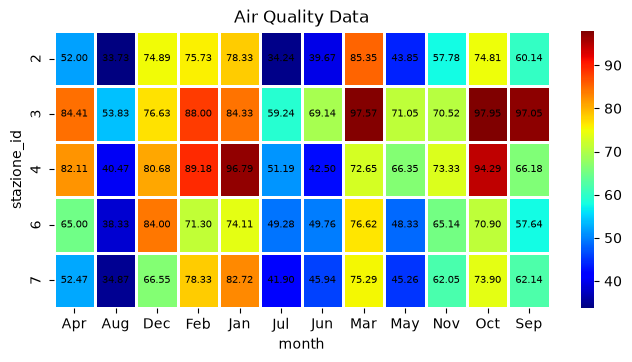

In [2]:
# Run it as it is: do not fix it here
no2 = (air[air["pollutant"] == "NO2"]
       .assign(month=lambda d:
               d["date"].dt.strftime("%b"))
       .groupby(["station_id", "month"])
       ["value"].mean()
       .unstack())        # columns sorted A-Z

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(no2, cmap="jet", annot=True,
            fmt=".2f", linewidths=1, ax=ax,
            annot_kws={"size": 7,
                       "color": "black"})
ax.set(title="Air Quality Data",
       xlabel="month", ylabel="stazione_id")
fig.savefig("flawed_chart.png", dpi=200,
            bbox_inches="tight")
plt.show()

## Step 2: your redesign

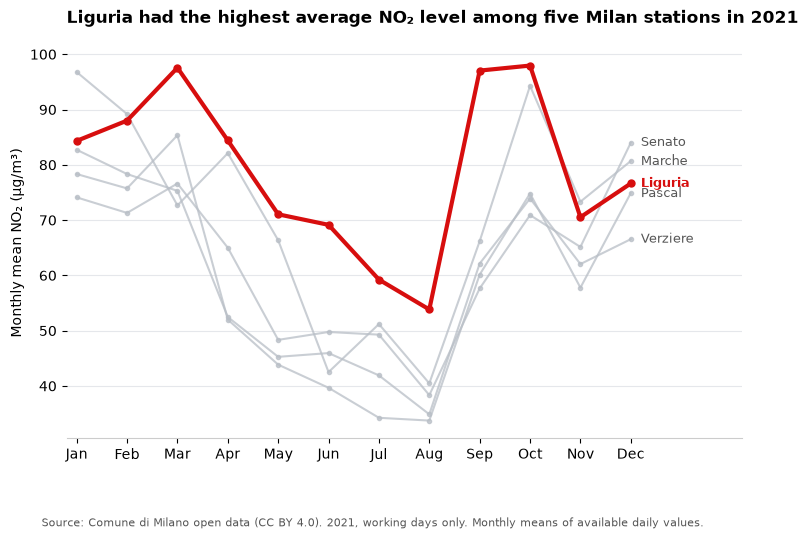

In [8]:

import calendar
import matplotlib.pyplot as plt

# Calculate monthly NO2 values using working days only
no2_named = (
    air[air["pollutant"] == "NO2"]
    .assign(month=lambda d: d["date"].dt.month)
    .groupby(["station", "month"], as_index=False)
    .agg(no2=("value", "mean"), days=("value", "size"))
)

# Order stations by their average monthly NO2 level
station_order = (
    no2_named.groupby("station")["no2"]
    .mean().sort_values(ascending=False).index.tolist()
)

# Use grey for comparison, and blue to highlight Liguria
fig, ax = plt.subplots(figsize=(10, 5.5))

for station in station_order:
    d = no2_named[no2_named["station"] == station].sort_values("month")

    highlighted = station == "Liguria"

    ax.plot(
        d["month"],
        d["no2"],
        color="#D70E0E" if highlighted else "#B8BEC6",
        linewidth=3 if highlighted else 1.5,
        marker="o",
        markersize=5 if highlighted else 3,
        alpha=1 if highlighted else 0.75,
        zorder=3 if highlighted else 1
    )

    # Label lines directly at December
    last = d.iloc[-1]
    ax.text(
        12.2, last["no2"], station,
        fontsize=9,
        fontweight="bold" if highlighted else "normal",
        color="#D70E0E" if highlighted else "#555555",
        va="center"
    )

# Calendar order
months = [calendar.month_abbr[i] for i in range(1, 13)]
ax.set_xticks(range(1, 13), months)
ax.set_xlim(0.8, 14.2)

# Informative title and axis label
ax.set_title(
    "Liguria had the highest average NO₂ level among five Milan stations in 2021",
    loc="left", fontsize=12, fontweight="bold", pad=18
)
ax.set_ylabel("Monthly mean NO₂ (µg/m³)", fontsize=10)
ax.set_xlabel("")

# Clean styling
ax.grid(axis="y", color="#E5E7EB", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

# Data source and important limitation
fig.text(
    0.1, 0.01,
    "Source: Comune di Milano open data (CC BY 4.0). "
    "2021, working days only. Monthly means of available daily values.",
    fontsize=8, color="#555555"
)

plt.subplots_adjust(bottom=0.17, right=0.80)

# Save chart
fig.savefig(
    "redesign.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


## Step 3: check it

In [4]:
# Before you submit (Deliverable B checklist):
#  [ ] the title states the message; units, source and "working days only" shown
#  [ ] months in calendar order; stations named, ordered by something meaningful
#  [ ] colour scale type matches the data (sequential / diverging / categorical)
#  [ ] readable in redesign_cvd.png (deuteranopia, protanopia, greyscale)
#  [ ] text has enough contrast; no false precision (how many decimals?)
#  [ ] every change explained with a principle in DeliverableB_Template.docx
from cvd_tools import cvd_check

# Check redesigned chart
cvd_check("redesign.png")

# Check original chart
cvd_check("flawed_chart.png")

CVD check written to redesign_cvd.png
CVD check written to flawed_chart_cvd.png


'flawed_chart_cvd.png'